# 01 — Data loading, cleaning and exploratory data analysis (EDA)

**Thesis:** Sentiment Analysis of Customer Reviews using Machine Learning Techniques
**Supervisor:** Mutaz AlShafeey
**Data:** the `val.csv` file of the Booking.com dataset (~200,000 reviews)

---

## What do we do in this notebook?

| # | Step | Thesis chapter |
|---|---|---|
| 1 | Environment and imports | — |
| 2 | Loading the data + **clarifying the name clash** | 4. Data Sources |
| 3 | Data quality: missing values, duplicates, lengths | 6.1 Preprocessing |
| 4 | Sentiment labels + **threshold sensitivity analysis** | 6.1 Preprocessing |
| 5 | Filtering and cleaning | 6.1 Preprocessing |
| 6 | Basic EDA figures | 9. EDA |
| 7 | **Descriptive statistics and crosstabs** | 9. EDA |
| 8 | Aspect preview | 7. ABSA / 9. EDA |
| 9 | 60/20/20 split and saving | 8. Data Split |

> **Every figure and table is saved automatically** to the `results/` folder.
> When you write the thesis, you copy from there — you do not re-run this notebook.

## 1. Environment and imports

In [36]:
# We run from the notebooks/ folder, so the parent folder has to be added to
# the path to be able to import the `src` package.
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import descriptives as ds
from src import aspects as asp
from src import text_analysis as ta
from src import evaluation as ev

# Reproducibility: THIS IS THE MOST IMPORTANT LINE of the notebook.
# Without it every run gives a slightly different result.
set_seed()
PATHS.ensure()

# Uniform figure style for the whole thesis (colours, font size, 300 DPI saving)
apply_plot_style()

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

print(f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"Seed: {CFG.random_seed}")
print(f"Data file: data/raw/{CFG.local_csv_name}")

pandas 3.0.6 | numpy 2.5.3
Seed: 42
Data file: data/raw/val.csv


## 2. Loading the data

### ⚠ Important name clarification — this has to be described in the thesis too

The file is called `val.csv` because it is the validation part of **Booking.com's own**
train/validation/test split. **For us, however, it is the whole working dataset**,
which WE split 60/20/20 into our own training/validation/test sets.

```
Booking.com's split:      train.csv    val.csv ←THIS IS WHAT WE USE    test.csv
                                          │
                          ┌───────────────┴───────────────┐
OUR split:             train (60%)   validation (20%)   test (20%)
```

The two "validation" words have **nothing to do with each other**. That is why in the
code the loaded dataset is called `booking_val_split`, not `validation`.

**What to write in chapter 4 of the thesis:** "For the experiments I used the
published validation subset of the Booking.com dataset (about 200,000 reviews).
It is a random subset of the full dataset and can therefore be considered
representative; it was chosen to reduce the computational cost."

> This is a completely legitimate decision — 200 thousand reviews are more than
> enough for this task. But it **has to be justified**, otherwise the reviewer
> will ask why you did not use the full data.

In [37]:
# The loader recognises the column names and prints what it found.
# If a column is missing, it warns — check the output!
df_raw = dl.load_dataset_by_name("booking_local")

print(f"\nLoaded: {len(df_raw):,} rows, {df_raw.shape[1]} columns")
print(f"Columns: {list(df_raw.columns)}")

15:39:09 | INFO    | src.data_loading | Loading from cache: booking_local_val__v2.parquet



Loaded: 203,787 rows, 20 columns
Columns: ['review_id', 'text', 'score', 'score_scale_max', 'dataset', 'review_positive', 'review_negative', 'guest_type', 'guest_country', 'room_nights', 'month', 'accommodation_id', 'accommodation_type', 'accommodation_score', 'accommodation_country', 'accommodation_star_rating', 'location_is_beach', 'location_is_ski', 'location_is_city_center', 'review_helpful_votes']


In [38]:
# Look at a few real rows — ALWAYS, for every dataset.
# Many problems are only noticed this way (placeholder texts, encoding errors).
df_raw.head(3)

,review_id,text,score,score_scale_max,dataset,review_positive,review_negative,guest_type,guest_country,room_nights,month,accommodation_id,accommodation_type,accommodation_score,accommodation_country,accommodation_star_rating,location_is_beach,location_is_ski,location_is_city_center,review_helpful_votes
0,booking_val_split_0,"Hope is relatively close to where I live, so this might just become a ""hop on the bike and cruise there for a weeke....",9.0,10.0,booking_val_split,"This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movi...",,Group,Jof,2,8,-225497943,Motel,7.7,Canada,3.0,0,0,0,0
1,booking_val_split_1,Close to the station and within walking distance of the centre,8.0,10.0,booking_val_split,Close to the station and within walking distance of the centre,,Solo traveller,Mejok,1,7,2110216461,Hotel,7.7,Netherlands,3.0,0,0,1,0
2,booking_val_split_2,"Excellent service. Excellent customer service, great location and the view, good breakfast spread, easy access to ci...",8.0,10.0,booking_val_split,"Excellent customer service, great location and the view, good breakfast spread, easy access to city centre, clean fa...",Kept on waking up in the middle of the night to a noisy boiler or something.,Family with children,Mejok,3,3,-1626991710,Hotel,7.9,United Kingdom,3.0,0,0,0,0


> **If the cell above raised an error** ("The score column was not found"), the
> column names of the CSV differ from the expected ones. The error message prints
> the actual names — extend the `_BOOKING_ALIASES` dictionary in `data_loading.py`
> with them.

## 3. Data quality

In [39]:
print("=== Types ===")
print(df_raw.dtypes.to_string())

print("\n=== Missing values ===")
miss = ds.missing_report(df_raw)
print(miss.to_string() if len(miss) else "No missing values.")

print("\n=== Duplicates (by text) ===")
n_dup = df_raw["text"].duplicated().sum()
print(f"{n_dup:,} rows ({n_dup/len(df_raw):.2%})")

print("\n=== Score ===")
print(df_raw["score"].describe().to_string())

=== Types ===
review_id                        str
text                          string
score                        float64
score_scale_max              float64
dataset                          str
review_positive                  str
review_negative                  str
guest_type                       str
guest_country                    str
room_nights                    int64
month                          int64
accommodation_id               int64
accommodation_type               str
accommodation_score          float64
accommodation_country            str
accommodation_star_rating    float64
location_is_beach              int64
location_is_ski                int64
location_is_city_center        int64
review_helpful_votes           int64

=== Missing values ===
               missing   share
guest_country      228  0.0011

=== Duplicates (by text) ===
409 rows (0.20%)

=== Score ===
count    203787.000000
mean          8.870705
std           1.154789
min           3.000000
25%   

In [40]:
# Text length — this decides how large a max_length BERT will need.
df_raw["n_chars"] = df_raw["text"].str.len()
df_raw["n_words"] = df_raw["text"].str.split().str.len()

print(df_raw[["n_chars", "n_words"]].describe(
    percentiles=[.5, .75, .9, .95, .99]).round(1).to_string())

q95 = df_raw["n_words"].quantile(0.95)
print(f"\n95% of the reviews are shorter than {q95:.0f} words.")
print(f"CFG.max_length = {CFG.max_length} tokens is therefore about "
      f"{'ENOUGH' if CFG.max_length > q95 * 1.3 else 'POSSIBLY TOO LITTLE — consider 256'}.")
print("(Rule of thumb: 1 word ≈ 1.3 tokens in English.)")

        n_chars   n_words
count  203787.0  203787.0
mean      278.4      49.1
std       237.5      43.7
min         0.0       0.0
50%       214.0      37.0
75%       354.0      63.0
90%       550.0      99.0
95%       716.0     130.0
99%      1184.0     215.0
max      3922.0     733.0

95% of the reviews are shorter than 130 words.
CFG.max_length = 256 tokens is therefore about ENOUGH.
(Rule of thumb: 1 word ≈ 1.3 tokens in English.)


In [41]:
# Concrete examples from the three score ranges of the current labelling
# (CFG.neg_threshold / CFG.pos_threshold).
# Note how little the middle band differs linguistically!
bands = [
    (0.0,                      CFG.neg_threshold,        "LOW (negative)"),
    (CFG.neg_threshold + 1e-9, CFG.pos_threshold - 1e-9, "MIDDLE (neutral)"),
    (CFG.pos_threshold,        10.0,                     "HIGH (positive)"),
]
for lo, hi, title in bands:
    sub = df_raw[(df_raw["score"] >= lo) & (df_raw["score"] <= hi)]
    print(f"\n{'='*70}\n{title} score ({lo:.1f}–{hi:.1f}) — {len(sub):,} reviews\n{'='*70}")
    for _, r in sub.sample(min(2, len(sub)), random_state=CFG.random_seed).iterrows():
        print(f"[{r['score']}] {r['text'][:220]}")


LOW (negative) score (0.0–7.0) — 26,647 reviews
[7.0] The apartments were clean and new. Location just perfect to visit Perugia
[7.0] Clean and Cozy. Nice design and easy check in, very pretty view and love the full kitchen and large space. Honestly I loved the room, just wish it would have been a more comfortable bed and larger bed. Was bummed there w

MIDDLE (neutral) score (7.0–9.0) — 45,736 reviews
[8.0] always like staying here. upgraded rooms to accommodate family having rooms near each other no hot water in the shower. - just a problem with the individual shower though
[8.0] Excellent views, great location. Close to shops, restaurants, beach. Lovely view. Clean apartment. Parking available.

HIGH (positive) score (9.0–10.0) — 131,404 reviews
[10.0] Exceptional. Will definitely stay again. Great location. The room was very clean and cozy. Very friendly staff. Great value for money.
[10.0] Fab stay - many thanks to Paula and her exceptional team. The room in the eaves was small b

## 4. Creating the sentiment labels

**This is one of the most important methodological decisions of the thesis.**

The data has no ready-made `positive / neutral / negative` label, only a 1–10
guest score. The three classes are derived from it (current setting in `config.py`):

| Condition | Label |
|---|---|
| `score ≤ 7` | negative |
| `7 < score < 9` | neutral |
| `score ≥ 9` | positive |

The 6/8 cut is common in the literature, but on this data it leaves only ~3% of the
reviews negative (see the table below) — too few for training. The cut is **arbitrary**
either way, which is why we run a **sensitivity analysis** below: how much does the
class distribution change with other thresholds? This is exactly the kind of
methodological thoroughness reviewers look for.

In [42]:
df = pp.add_sentiment_labels(df_raw)

dist = df["sentiment"].value_counts().reindex(list(CFG.labels))
summary = pd.DataFrame({"count": dist, "share": (dist / len(df)).round(4)})
display(summary)

imbalance = dist.max() / dist.min()
print(f"Imbalance ratio: {imbalance:.1f}x")
print("=> That is why MACRO-F1 is our main metric (not accuracy),")
print("   and why the models use class_weight='balanced'.")

,count,share
sentiment,,
negative,26647,0.1308
neutral,45736,0.2244
positive,131404,0.6448


Imbalance ratio: 4.9x
=> That is why MACRO-F1 is our main metric (not accuracy),
   and why the models use class_weight='balanced'.


The distinct values of the score and their frequencies:
           count   share
score                   
3.000000      32  0.0002
4.000000     129  0.0006
5.000000    1246  0.0061
6.000000    4742  0.0233
6.666675       1  0.0000
7.000000   20497  0.1006
7.083325       5  0.0000
7.500000       1  0.0000
7.916675       3  0.0000
8.000000   45723  0.2244
8.333325       2  0.0000
8.750000       2  0.0000
9.000000   50961  0.2501
9.166675       5  0.0000
9.583325      12  0.0001
10.000000  80426  0.3947

Mean: 8.87 | Median: 9.0
  P05: 7.0
  P10: 7.0
  P25: 8.0
  P50: 9.0
  P75: 10.0


15:39:12 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_score_distribution.png


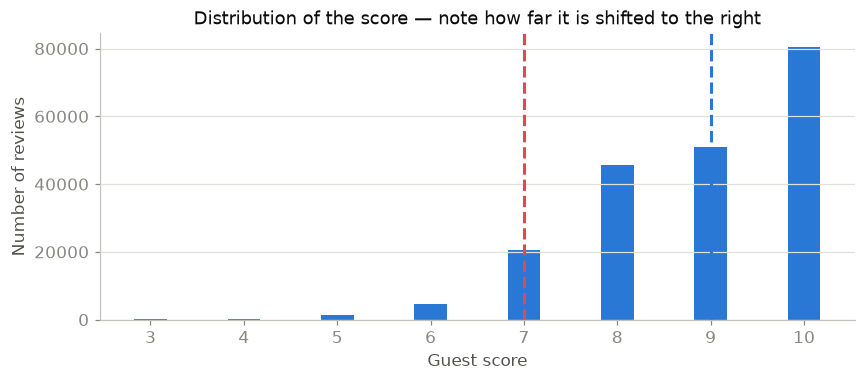

In [43]:
# FIRST, let us look at how the score is distributed. This decides whether a
# given threshold pair works on this data at all.
vc = df_raw["score"].value_counts().sort_index()
print("The distinct values of the score and their frequencies:")
print(pd.DataFrame({"count": vc, "share": (vc / len(df_raw)).round(4)}).to_string())

print(f"\nMean: {df_raw['score'].mean():.2f} | Median: {df_raw['score'].median():.1f}")
for q in [0.05, 0.10, 0.25, 0.50, 0.75]:
    print(f"  P{int(q*100):02d}: {df_raw['score'].quantile(q):.1f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(vc.index, vc.values, width=0.35, color="#2a78d6")
ax.axvline(CFG.neg_threshold, color=SENTIMENT_COLORS["negative"], ls="--", lw=2)
ax.axvline(CFG.pos_threshold, color=SENTIMENT_COLORS["positive"], ls="--", lw=2)
ax.set(xlabel="Guest score", ylabel="Number of reviews",
       title="Distribution of the score — note how far it is shifted to the right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
ev.save_figure("01_score_distribution")
plt.show()

In [44]:
# COMPARISON OF LABELLING RULES
#
# This table is one of the key exhibits of chapter 6.1 of the thesis. It shows
# that the choice of threshold is not a technical side issue but substantially
# determines the difficulty of the task.
#
# Two kinds of logic appear in it:
#   FIXED threshold     -> ABSOLUTE satisfaction ("below 7 = bad experience")
#   QUANTILE threshold  -> RELATIVE satisfaction ("the bottom quarter")
# Both are defensible, but they do NOT claim the same thing — the thesis has to
# state which one was chosen and why.
comp = pp.label_distribution_report(df_raw["score"], df_raw["score_scale_max"])
display(comp)
ev.save_table(comp, "01_label_scheme_comparison")

print("\nWhat to watch for:")
print("  • 'smallest class (n)': fine-tuning BERT needs at least a few thousand")
print("    examples per class. A few hundred is too few.")
print("  • 'imbalance ratio': the ratio of the largest and the smallest class.")
print("    Above 10x the model tends to simply predict the majority.")
print("\n=> Choose the row you can argue for, and enter its neg_threshold /")
print("   pos_threshold values in config.py.")

15:39:12 | INFO    | src.preprocessing | The score is discrete: 16 distinct values, 8 of them integers. Only thresholds on integer boundaries give a different split.


,thresholds,neg scores,neu scores,pos scores,negative,neutral,positive,smallest class (n),imbalance ratio
scheme,,,,,,,,,
A) 6 / 8 — strict,6 / 8,3–6,7,8–10,0.0302,0.1006,0.8692,6149,28.8
B) 7 / 9 — balanced,7 / 9,3–7,8,9–10,0.1308,0.2244,0.6448,26647,4.9
C) 7 / 10 — wide middle,7 / 10,3–7,8–9,10,0.1308,0.4746,0.3947,26647,3.6
D) 8 / 10 — relative,8 / 10,3–8,9,10,0.3552,0.2502,0.3947,50982,1.6


15:39:12 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_label_scheme_comparison.csv



What to watch for:
  • 'smallest class (n)': fine-tuning BERT needs at least a few thousand
    examples per class. A few hundred is too few.
  • 'imbalance ratio': the ratio of the largest and the smallest class.
    Above 10x the model tends to simply predict the majority.

=> Choose the row you can argue for, and enter its neg_threshold /
   pos_threshold values in config.py.


## 5. Filtering and cleaning

In [45]:
# build_dataset() does: filtering -> labelling -> two kinds of cleaning.
#
# The two kinds of cleaning are INTENTIONAL:
#   text_clean  -> for TF-IDF: aggressive (lowercase, punctuation out, stopwords
#                  out, lemmatisation). Noise filtering helps the bag-of-words model.
#   text_bert   -> for BERT: minimal. The transformer learns from context;
#                  if you threw out the negation, "not clean" would become "clean",
#                  i.e. you would teach it the OPPOSITE.
#
# On 200k rows this runs for a few minutes (lemmatisation is the slow part).
df = pp.build_dataset(df_raw, classic_clean=True, minimal_clean=True, balance="none")

df["n_words"] = df["text"].str.split().str.len()
df["n_chars"] = df["text"].str.len()

print(f"\nFinal size: {len(df):,} rows")
print(df["sentiment"].value_counts().to_string())

15:39:16 | INFO    | src.preprocessing | --- Filtering log ---
15:39:16 | INFO    | src.preprocessing | start                                           203787  (+0)
15:39:16 | INFO    | src.preprocessing | short texts (<10 chars) removed                 203662  (-125)
15:39:16 | INFO    | src.preprocessing | extremely long texts (>5000 chars) removed      203662  (+0)
15:39:16 | INFO    | src.preprocessing | duplicates removed                              203340  (-322)
15:39:16 | INFO    | src.preprocessing | non-English texts removed                       203328  (-12)
15:39:20 | INFO    | src.preprocessing | Running classical cleaning on 203328 rows (this may take a while)...



Final size: 203,328 rows
sentiment
positive    131103
neutral      45614
negative     26611


In [46]:
# What DID the cleaning do? Put this example into chapter 6.1 of the thesis!
ex = df.iloc[0]
print("ORIGINAL:\n ", ex["text"][:280])
print("\nFor BERT (minimal cleaning):\n ", ex["text_bert"][:280])
print("\nFor TF-IDF (full cleaning):\n ", ex["text_clean"][:280])

ORIGINAL:
  Hope is relatively close to where I live, so this might just become a "hop on the bike and cruise there for a weeke. This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movie theatre just around the corner and as well a 

For BERT (minimal cleaning):
  Hope is relatively close to where I live, so this might just become a "hop on the bike and cruise there for a weeke. This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movie theatre just around the corner and as well a 

For TF-IDF (full cleaning):
  hope relatively close live might become hop bike cruise weeke motel center hope get grocery restaurant pub food short distance movie theatre around corner well small nice park next building look like could use bit love outside room extraordinarily clean especially motel absolutel


In [47]:
# TRUNCATION CHECK — for setting BERT's max_length
#
# The text is built as:  title . positive_part   negative_part
# The tokenizer cuts off the END, so the NEGATIVE content goes first.
# If this affects many reviews, the model systematically sees fewer negative
# signals — which would bias it towards the positive class.
for L in [128, 192, 256, 384]:
    rep = pp.truncation_report(df, max_length=L, text_col="text_bert")
    tr = rep.loc["truncated"]
    print(f"max_length={L:3d}  ->  truncated: {tr['share']:6.2%} ({int(tr['count']):,} reviews)")

print(f"\nCurrent setting: CFG.max_length = {CFG.max_length}")
print("\nDetailed breakdown with the current value:")
display(pp.truncation_report(df, max_length=CFG.max_length, text_col="text_bert"))
print("If the class proportions in the 'truncated' row DIFFER from the 'fits' row,")
print("truncation biases the data -> increase max_length.")

max_length=128  ->  truncated: 10.67% (21,694 reviews)
max_length=192  ->  truncated:  3.60% (7,322 reviews)
max_length=256  ->  truncated:  1.40% (2,846 reviews)
max_length=384  ->  truncated:  0.31% (640 reviews)

Current setting: CFG.max_length = 256

Detailed breakdown with the current value:


,share,count,positive,neutral,negative
fits,0.986,200482,0.6464,0.2241,0.1295
truncated,0.014,2846,0.5309,0.2400,0.2291


If the class proportions in the 'truncated' row DIFFER from the 'fits' row,
truncation biases the data -> increase max_length.


## 6. Basic EDA figures

15:39:52 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_eda_overview.png


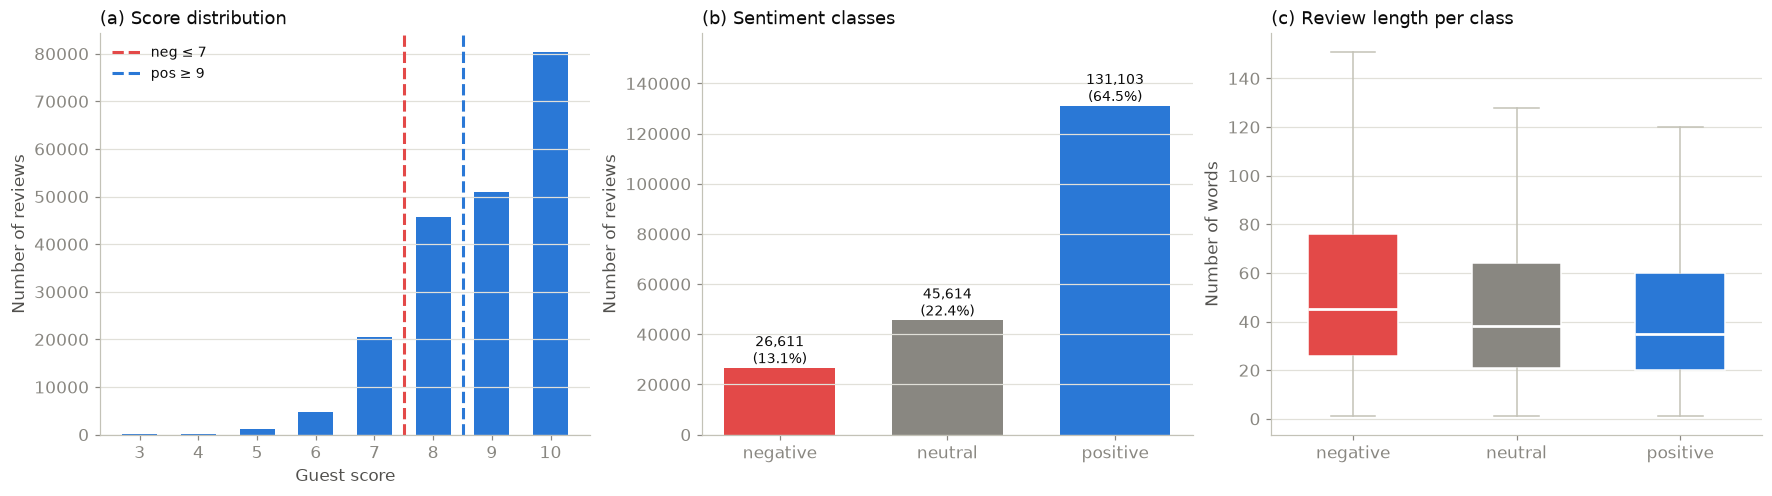

In [48]:
order = list(CFG.labels)
# Three panels with their own y-axes, laid out with constrained_layout so that
# the axis labels do not overlap each other.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)

# ---- (a) Score distribution with the thresholds ----
# The score is DISCRETE (integer values), so a bar chart, not a histogram.
# A histogram would draw arbitrary bin boundaries between the discrete values.
vc = df["score"].round().value_counts().sort_index()
axes[0].bar(vc.index, vc.values, width=0.6, color="#2a78d6")
axes[0].axvline(CFG.neg_threshold + 0.5, color=SENTIMENT_COLORS["negative"],
                ls="--", lw=2, label=f"neg ≤ {CFG.neg_threshold:g}")
axes[0].axvline(CFG.pos_threshold - 0.5, color=SENTIMENT_COLORS["positive"],
                ls="--", lw=2, label=f"pos ≥ {CFG.pos_threshold:g}")
axes[0].set(xlabel="Guest score", ylabel="Number of reviews")
axes[0].set_title("(a) Score distribution", loc="left")
axes[0].legend(fontsize=9)
axes[0].grid(axis="x", visible=False)

# ---- (b) Class distribution ----
counts = df["sentiment"].value_counts().reindex(order)
axes[1].bar(order, counts.values, color=[SENTIMENT_COLORS[l] for l in order], width=0.66)
for i, v in enumerate(counts.values):
    axes[1].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
axes[1].set(ylabel="Number of reviews")
axes[1].set_title("(b) Sentiment classes", loc="left")
axes[1].margins(y=0.22)
axes[1].grid(axis="x", visible=False)

# ---- (c) Text length per class ----
# NOTE: from matplotlib 3.9 the `labels` parameter of boxplot is `tick_labels`.
# To stay version-independent neither is passed — the ticks are set separately.
data = [df.loc[df["sentiment"].astype(str) == l, "n_words"].values for l in order]
bp = axes[2].boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                     medianprops=dict(color="white", linewidth=1.8))
for patch, l in zip(bp["boxes"], order):
    patch.set_facecolor(SENTIMENT_COLORS[l])
    patch.set_edgecolor(INK["surface"])
for part in ("whiskers", "caps"):
    for art in bp[part]:
        art.set_color(INK["axis"])
axes[2].set_xticks(range(1, len(order) + 1), order)
axes[2].set(ylabel="Number of words")
axes[2].set_title("(c) Review length per class", loc="left")
axes[2].grid(axis="x", visible=False)

ev.save_figure("01_eda_overview")
plt.show()

In [49]:
# Quantify what you see in figure (c) — this goes into the text.
lens = df.groupby("sentiment", observed=True)["n_words"].agg(["count", "mean", "median"]).round(1)
display(lens)

neg_m = lens.loc["negative", "median"]; pos_m = lens.loc["positive", "median"]
print(f"The median length of negative reviews is {neg_m:.0f} words, of positive ones {pos_m:.0f}.")
print("\nTypical observation: NEGATIVE reviews are longer — the dissatisfied guest")
print("describes the problem in detail, while a positive review is often a few words.")
print("This is a predictive signal on its own, and it will come back in the error analysis.")

,count,mean,median
sentiment,,,
negative,26611,59.4,45.0
neutral,45614,50.2,38.0
positive,131103,46.8,35.0


The median length of negative reviews is 45 words, of positive ones 35.

Typical observation: NEGATIVE reviews are longer — the dissatisfied guest
describes the problem in detail, while a positive review is often a few words.
This is a predictive signal on its own, and it will come back in the error analysis.


### Which words are characteristic of each class?

The obvious approach would be to list the **most frequent** words per class. That,
however, gives a useless result: the same words would lead in all three classes
(*room, location, staff, good*), because frequent words are frequent everywhere.

The right question is not *which words are frequent in negative reviews*, but
**which words are more frequent in the negative class than in the others**. For this
we use the **weighted log-odds ratio** (Monroe, Colaresi & Quinn, 2008):

1. **log-odds**: how many times more likely the term is in this class than in the
   others — logarithmised to make it symmetric.
2. **normalising to a z-score**: the ratio of rare terms can spike by chance, so we
   divide by the standard deviation of the estimate. This way the top of the list
   holds terms that are **frequent AND distinctive**.

Put the reference into the bibliography — this is an established, citable method,
not a home-made solution.

15:40:06 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_top_words_by_sentiment.png


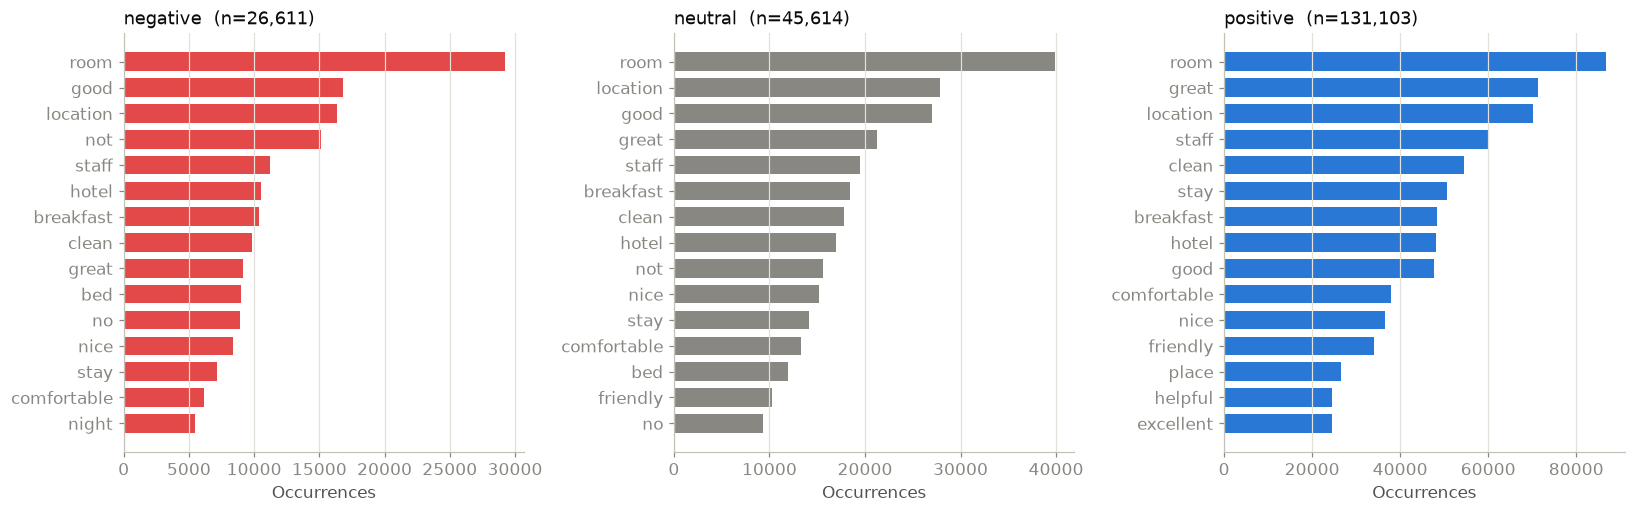

In [50]:
# Most frequent terms per class — the first look into
# WHAT drives the sentiment.
from sklearn.feature_extraction.text import CountVectorizer

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, label in zip(axes, CFG.labels):
    texts = df.loc[df["sentiment"].astype(str) == label, "text_clean"]
    if len(texts) == 0:
        continue
    cv = CountVectorizer(max_features=15, ngram_range=(1, 2), min_df=3)
    X = cv.fit_transform(texts)
    freq = pd.Series(np.asarray(X.sum(axis=0)).ravel(),
                     index=cv.get_feature_names_out()).sort_values()
    ax.barh(freq.index, freq.values, color=SENTIMENT_COLORS[label], height=0.72)
    ax.set_title(f"{label}  (n={len(texts):,})", loc="left")
    ax.set_xlabel("Occurrences")
    ax.grid(axis="y", visible=False)

plt.tight_layout()
ev.save_figure("01_top_words_by_sentiment")
plt.show()

15:40:18 | INFO    | src.text_analysis | Vocabulary: 15619 terms (1-2-gram), 7647315 tokens in total
15:40:18 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_distinctive_terms.csv
15:40:19 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_distinctive_terms.png


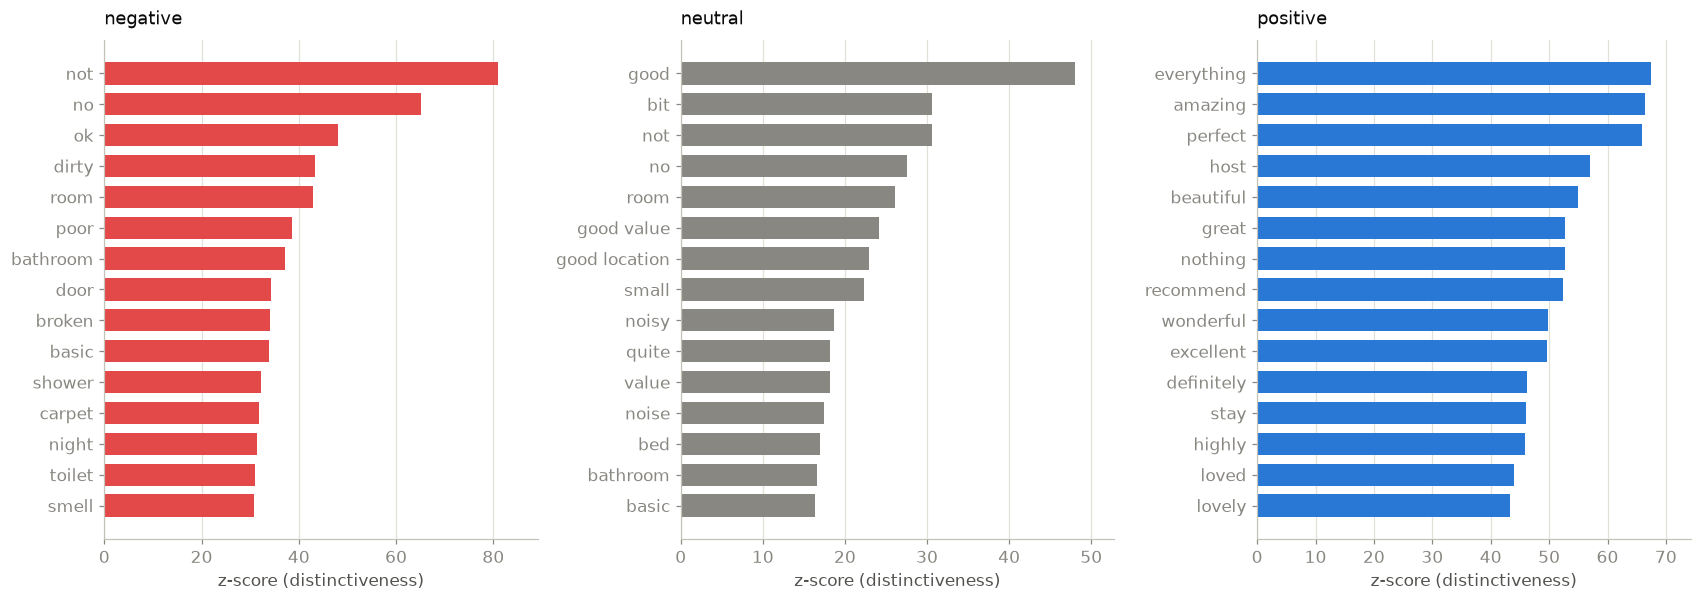

In [51]:
# Distinctive terms per class.
# ngram_range=(1,2): words AND word pairs. The word pairs are what matters —
# "not clean" exists only as a bigram.
#
# IMPORTANT: the `text_clean` column is used, where the negation words were KEPT
# (keep_negations=True). Had they been dropped, this whole analysis would be meaningless.
dist = ta.distinctive_terms(
    df["text_clean"], df["sentiment"],
    ngram_range=(1, 2), top_n=15, min_count=50,
)
ev.save_table(dist, "01_distinctive_terms")

ta.plot_distinctive_terms(dist, top_n=15, save_as="01_distinctive_terms")
plt.show()

15:40:45 | INFO    | src.text_analysis | Vocabulary: 14435 terms (2-3-gram), 2739556 tokens in total
15:40:45 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_distinctive_multiword.csv
15:40:46 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_distinctive_multiword.png


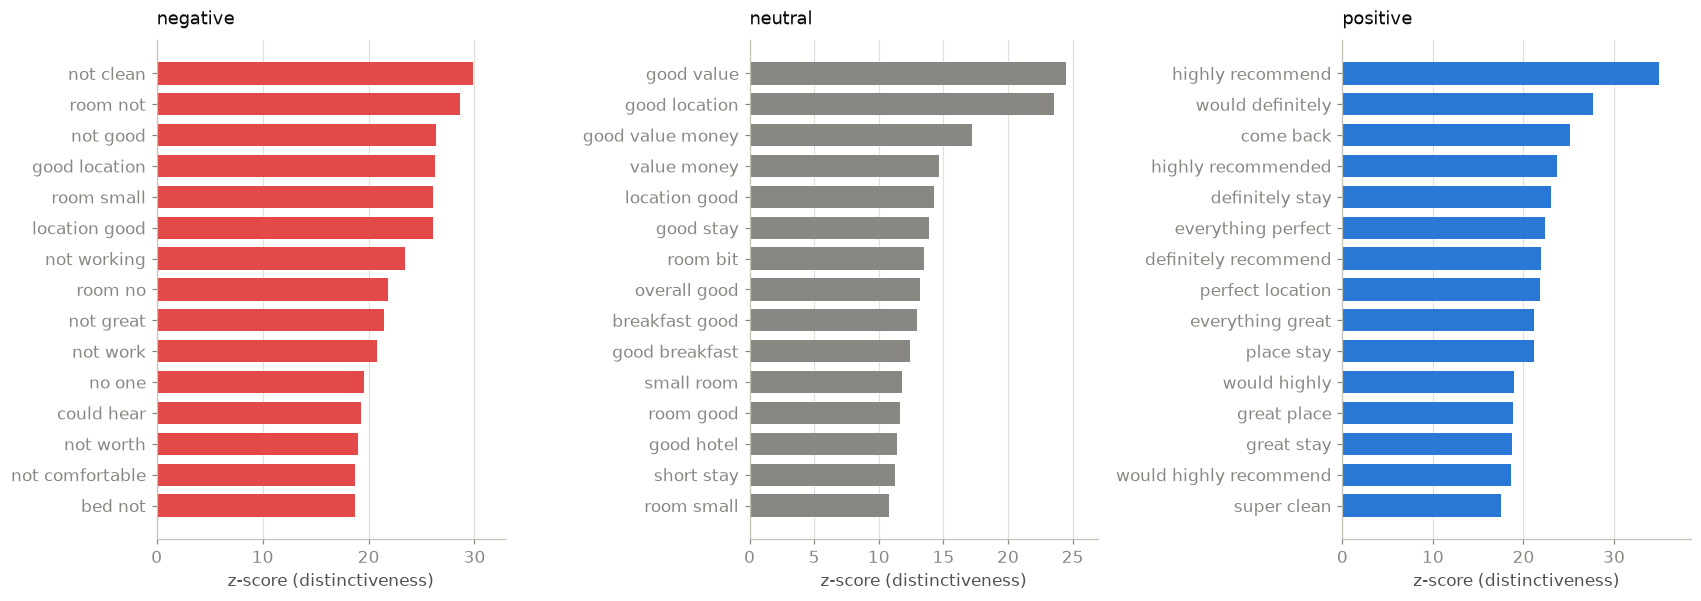


=== NEGATIVE — multi-word terms ===
         term   z_score  count_in_class    ratio
    not clean 29.894438             457 8.187488
     room not 28.592536             848 3.345316
     not good 26.335244             585 3.985309
good location 26.245319            2662 1.770161
   room small 26.098628             834 2.975194
location good 26.042761            1454 2.200165
  not working 23.407982             472 3.909519
      room no 21.839409             492 3.362342
    not great 21.440310             397 3.901123
     not work 20.807296             316 4.626221

=== NEUTRAL — multi-word terms ===
            term   z_score  count_in_class    ratio
      good value 24.504786            2386 1.863766
   good location 23.533193            3925 1.571599
good value money 17.252094            1265 1.822940
     value money 14.662577            2975 1.373542
   location good 14.268115            1760 1.503278
       good stay 13.887991             566 2.100539
        room bit 13.4796

In [52]:
# === MULTI-WORD TERMS ONLY ===
# The previous cell used the (1,2) range, where single-word terms crowd out the
# word pairs because they are more frequent. Here the lower bound is raised to 2,
# so ONLY two- and three-word terms compete with each other.
#
# This shows what the single-word representation loses:
# "not clean", "no hot water", "would not recommend" — meanings that cannot be
# assembled from a single word.

multi = ta.distinctive_terms(
    df["text_clean"], df["sentiment"],
    ngram_range=(2, 3),      # <- THIS is the difference: no unigrams
    top_n=15,
    min_count=50,            # reasonable on 200k rows; lower it on a smaller sample
)
ev.save_table(multi, "01_distinctive_multiword")

ta.plot_distinctive_terms(multi, top_n=15, save_as="01_distinctive_multiword")
plt.show()

# In table form, with the numbers
for cls in CFG.labels:
    sub = multi[multi["sentiment"] == cls].head(10)
    print(f"\n=== {cls.upper()} — multi-word terms ===")
    print(sub[["term", "z_score", "count_in_class", "ratio"]].to_string(index=False))

In [53]:
# The same in a table, so you can see the numbers too
for cls in CFG.labels:
    sub = dist[dist["sentiment"] == cls].head(10)
    print(f"\n=== {cls.upper()} ===")
    print(sub[["term", "z_score", "count_in_class", "ratio"]]
          .to_string(index=False))
print("\n'ratio' = how many times more frequent in this class than in the others")


=== NEGATIVE ===
    term   z_score  count_in_class    ratio
     not 81.055996           15132 2.152476
      no 65.161795            8940 2.247461
      ok 47.984273            2076 3.928182
   dirty 43.286535            1098 7.070505
    room 42.989084           29248 1.313593
    poor 38.538315            1075 5.010227
bathroom 37.108216            5449 1.775132
    door 34.214792            2704 2.163971
  broken 34.089864             782 5.544229
   basic 33.917125            1361 3.141973

=== NEUTRAL ===
         term   z_score  count_in_class    ratio
         good 48.006375           26977 1.410089
          bit 30.653504            5758 1.634088
          not 30.641186           15625 1.332982
           no 27.564702            9283 1.403628
         room 26.145497           39930 1.160162
   good value 24.099275            2386 1.846558
good location 22.980163            3925 1.557089
        small 22.364078            5599 1.427218
        noisy 18.624252            1811 

### Negation analysis — when do words have to be put together?

This question is the core of **RQ2** of the thesis, and it gets its quantitative
answer here.

By default TF-IDF is a **bag-of-words** model: it does not know whether `not`
stands before `good` or in another sentence. If it used only single-word features
(unigrams), `"not good"` would look exactly like `"good"` — plus a `not`.

The cells below measure **how much this really matters**:

1. which negated word pairs are the most frequent, and which class they fall into;
2. the same word on its own vs. negated — how far it shifts towards the negative class;
3. how much more distinctive the vocabulary becomes if word pairs are allowed.

The ablation study of notebook 02 will measure the same question in **model
performance**. This is the linguistic side, that is the engineering side — together
they give a complete answer.

In [54]:
# 1) Word pairs starting with a negation
neg_bi = ta.negation_bigrams(df["text_clean"], df["sentiment"],
                             top_n=25, min_count=50)
display(neg_bi)
ev.save_table(neg_bi, "01_negation_bigrams")

print("\nReading: 'neg_lift' = how many times the negative share of the word pair")
print("is the dataset average. Above 1.0 it pulls in the negative direction.")

,total,negative,neutral,positive,neg_lift
bigram,,,,,
not clean,819,0.5580,0.2784,0.1636,4.2635
not work,759,0.4163,0.3057,0.2780,3.1811
no one,746,0.3995,0.2909,0.3097,3.0522
not good,1537,0.3806,0.3155,0.3038,2.9082
not working,1255,0.3761,0.3275,0.2964,2.8737
not great,1057,0.3756,0.3377,0.2867,2.8698
not bad,724,0.3660,0.3204,0.3135,2.7967
not comfortable,911,0.3600,0.3425,0.2975,2.7510
no breakfast,752,0.3085,0.3059,0.3856,2.3573


15:40:54 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_negation_bigrams.csv



Reading: 'neg_lift' = how many times the negative share of the word pair
is the dataset average. Above 1.0 it pulls in the negative direction.


,n (plain),negative share (plain),n (negated),negative share (negated),difference,lift (negated)
word,,,,,,
clean,72172,0.1111,831,0.5475,0.4364,4.1836
friendly,44970,0.0989,309,0.3819,0.2830,2.9178
nice,46361,0.1364,315,0.3905,0.2541,2.9835
recommend,13383,0.0344,251,0.2869,0.2524,2.1918
comfortable,49683,0.1030,920,0.3533,0.2502,2.6992
hot water,1880,0.2069,338,0.4497,0.2428,3.4361
helpful,32380,0.0862,238,0.3067,0.2205,2.3436
great,70992,0.0914,1371,0.2830,0.1916,2.1624
quiet,16419,0.1012,39,0.2564,0.1552,1.9592


15:41:14 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_negation_effect.csv
15:41:15 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_negation_effect.png


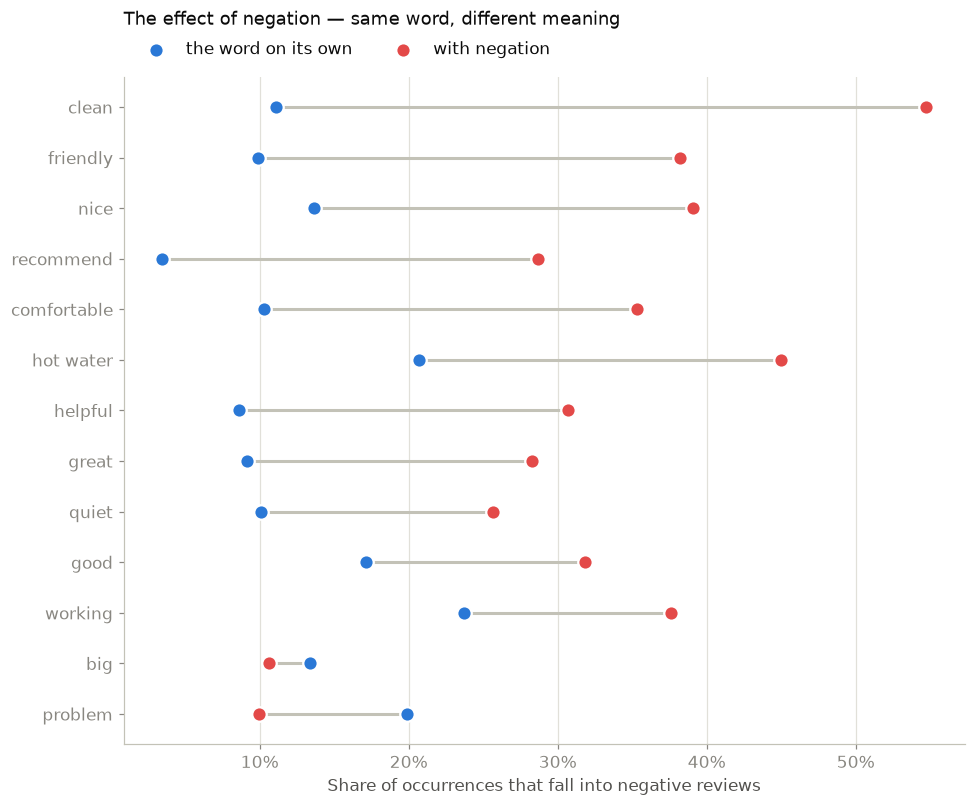

In [55]:
# 2) THE KEY EXPERIMENT: the same word on its own vs. negated
neg_effect = ta.compare_with_without_negation(df["text_clean"], df["sentiment"])
display(neg_effect)
ev.save_table(neg_effect, "01_negation_effect")

ta.plot_negation_effect(neg_effect, save_as="01_negation_effect")
plt.show()

> **This table is one of your strongest results.** If, say, 8% of the occurrences
> of `"good"` fall into negative reviews but 60% of those of `"not good"`, you have
> proven that the unigram representation loses something that is
> **quantitatively significant** — not just in principle.
>
> Write this into the log with concrete numbers. In the ablation of notebook 02 you
> will tie the macro-F1 difference to it: "dropping the negation words lowered the
> score by X points, which is consistent with the negative share of the negated forms
> being Y times that of the plain forms".

In [56]:
# 3) How much richer is the vocabulary at a higher n-gram level?
# (This runs for a few minutes, because it builds the vocabulary three times.)
ngram_cmp = ta.ngram_level_comparison(df["text_clean"], df["sentiment"], min_count=50)
display(ngram_cmp)
ev.save_table(ngram_cmp, "01_ngram_levels")

print("\nThe 'multi-word share in top-50' column shows what share of the most")
print("characteristic terms are multi-word. If it is high, the word pairs carry real")
print("information -> the (1,2) ngram_range is justified in TF-IDF.")

15:41:18 | INFO    | src.text_analysis | Vocabulary: 4408 terms (1-1-gram), 5318061 tokens in total
15:41:31 | INFO    | src.text_analysis | Vocabulary: 15619 terms (1-2-gram), 7647315 tokens in total
15:42:01 | INFO    | src.text_analysis | Vocabulary: 18843 terms (1-3-gram), 8057617 tokens in total


,top-50 mean z,multi-word share in top-50,example (negative)
n-gram level,,,
"unigram (1,1)",26.742,0.000,—
"uni+bigram (1,2)",27.587,0.173,"not clean, room not, not good"
"uni+bi+trigram (1,3)",27.686,0.180,"not clean, room not, not good"


15:42:01 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_ngram_levels.csv



The 'multi-word share in top-50' column shows what share of the most
characteristic terms are multi-word. If it is high, the word pairs carry real
information -> the (1,2) ngram_range is justified in TF-IDF.


## 7. Descriptive statistics and crosstabs

Here we go beyond "how many rows does the data have". The metadata of Booking.com
(country, accommodation type, guest type, star rating) make it possible to examine
sentiment **along these dimensions** — which is what an analyst of a hotel chain
would do too.

### The central measure: LIFT

It is not enough to say "35% of hostels are negative". You need to know whether that is a lot:

```
lift = negative share of the group / negative share of the whole dataset

lift = 1.0  →  exactly average
lift = 1.4  →  negative 40% more often than average
lift = 0.7  →  30% less often
```

This way groups of different sizes are comparable, and a single number tells where
the problem is.

### A word about the colours

The figures use a **red–grey–blue** scale, not red–green. Red-green colour blindness
affects about 8% of men and merges exactly these two colours — in a printed thesis
this is a real readability problem. The red–blue pair stays distinguishable with
colour blindness too.

In [57]:
# A star rating of 0 is NOT "zero stars" but "no rating".
# If it is not handled, it would appear as a category of its own and look like
# the worst one when sorting — while it is missing data.
df = ds.prepare_star_rating(df)

# The guest_country column is PSEUDONYMISED in the Booking release (Fuxa, Xazas,
# Nukeye...). For privacy reasons these are not real country names. Differences
# between the groups are still measurable, but it CANNOT be said which country is
# which — so it is left out of the crosstabs. If you use it anyway, this limitation
# has to be stated separately in the thesis.
if "guest_country" in df.columns:
    n_anon = df["guest_country"].nunique()
    print(f"guest_country: {n_anon} unique values, pseudonymised — left out of the analysis.")
    print("Examples:", df["guest_country"].dropna().unique()[:6].tolist())

15:42:01 | INFO    | src.descriptives | Star rating: 64997 rows (32.0%) had the value 0 -> moved to the 'n/a' category.


guest_country: 209 unique values, pseudonymised — left out of the analysis.
Examples: ['Jof', 'Mejok', 'Zuc', 'Sajeb', 'Dawal', 'Gobuf']


In [58]:
# Overview table — this goes into chapters 4 and 9 of the thesis
overview = ds.dataset_overview(df)
display(overview)
ev.save_table(overview, "01_dataset_overview")

,Value
Metric,
Number of reviews,"203,328"
Unique properties,"5,000"
Number of countries,120
Accommodation types,24
Mean score,8.87
Median score,9.00
Score standard deviation,1.16
Mean review length (words),49.2
Median review length (words),37


15:42:01 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_dataset_overview.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/01_dataset_overview.csv')

In [59]:
# Profile of the numeric columns
prof = ds.numeric_profile(df)
display(prof)
ev.save_table(prof, "01_numeric_profile")

,count,mean,std,min,5%,25%,50%,75%,95%,max
score,203328.0,8.87,1.16,3.0,7.0,8.0,9.0,10.0,10.0,10.0
n_words,203328.0,49.21,43.67,1.0,9.0,21.0,37.0,63.0,130.0,733.0
n_chars,203328.0,278.88,237.37,10.0,55.0,126.0,214.0,355.0,716.0,3922.0
room_nights,203328.0,2.59,2.39,1.0,1.0,1.0,2.0,3.0,7.0,112.0
accommodation_score,203328.0,8.38,0.74,4.2,7.0,8.0,8.4,8.9,9.5,10.0
review_helpful_votes,203328.0,0.14,0.78,0.0,0.0,0.0,0.0,0.0,1.0,87.0


15:42:01 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_numeric_profile.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/01_numeric_profile.csv')

15:42:02 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_counts_accommodation_country.png


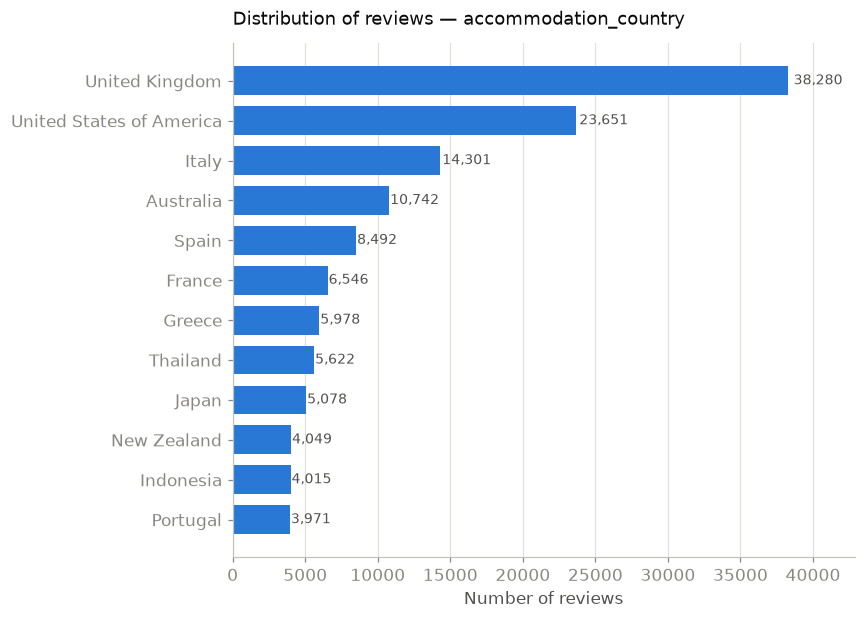

15:42:02 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_counts_accommodation_type.png


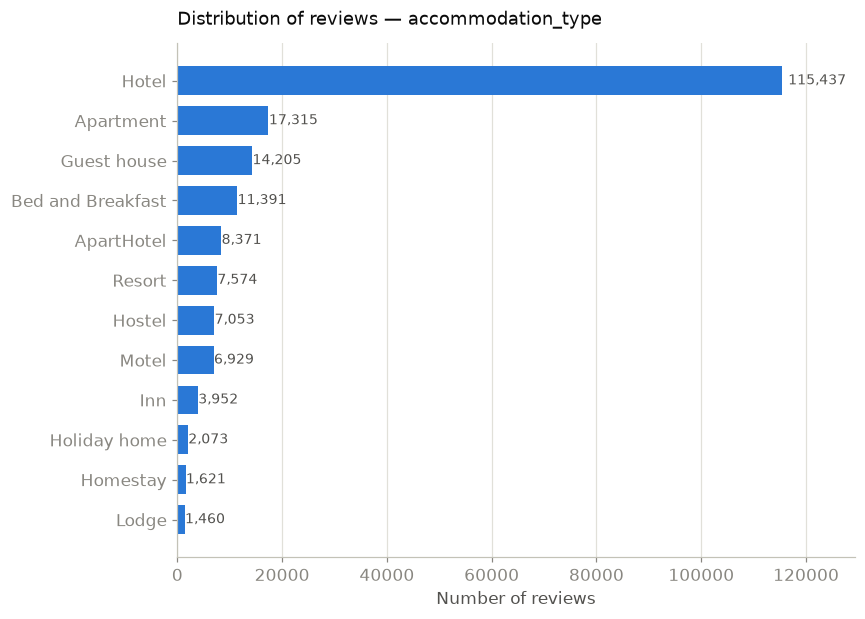

15:42:02 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_counts_guest_type.png


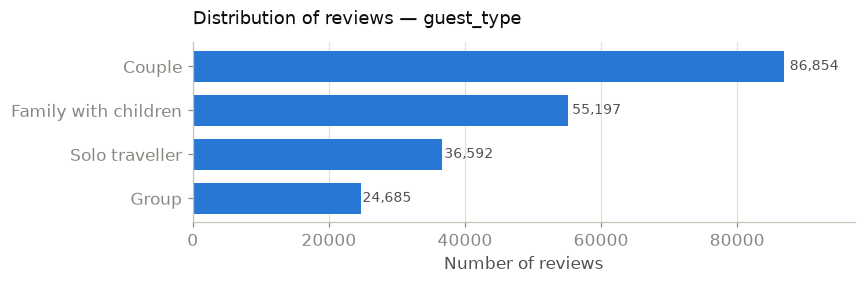

In [60]:
# Which category has the most reviews? (You need to know this before
# interpreting any group comparison.)
for col in ["accommodation_country", "accommodation_type", "guest_type"]:
    if col in df.columns:
        ds.plot_top_categories(df, col, top_n=12,
                               title=f"Distribution of reviews — {col}",
                               save_as=f"01_counts_{col}")
        plt.show()

In [61]:
# === THE MAIN CROSSTAB RUN ===
# For every available dimension: table + figure, saved automatically.
#
# min_count=200: categories with fewer reviews than this are dropped.
#   WHY? Because a 50% negative share computed from 12 reviews is statistical
#   noise, not a finding. This threshold has to be mentioned in the thesis.
crosstabs = ds.run_all_crosstabs(
    df, min_count=200, top_n=12, save=True,
    dims={k: v for k, v in {
        "accommodation_country": "accommodation country",
        "accommodation_type": "accommodation type",
        "guest_type": "guest type",
        "accommodation_star_rating": "star rating",
    }.items() if k in df.columns},
)

print(f"\n{len(crosstabs)} crosstabs created.")

15:42:03 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_crosstab_accommodation_country.csv
15:42:03 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_crosstab_accommodation_country.png
15:42:03 | INFO    | src.descriptives | accommodation_country        12 categories, neg_lift range 0.49–1.48
15:42:03 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_crosstab_accommodation_type.csv
15:42:04 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_crosstab_accommodation_type.png
15:42:04 | INFO    | src.descriptives | accommodation_type           12 categories, neg_lift range 0.25–1.52
15:42:04 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results


4 crosstabs created.


In [62]:
# A detailed look at the accommodation type — typically the spread is largest here
if "accommodation_type" in crosstabs:
    display(crosstabs["accommodation_type"])
    print("\nReading:")
    print("  neg_lift > 1  ->  this accommodation type DRIVES COMPLAINTS")
    print("  neg_lift < 1  ->  DRIVES SATISFACTION")

,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_score
accommodation_type,,,,,,,,
Motel,6929,0.0341,0.1993,0.2589,0.5418,1.5229,0.8402,8.5780
Resort,7574,0.0373,0.1583,0.2147,0.6270,1.2096,0.9724,8.7873
Hotel,115437,0.5677,0.1499,0.2467,0.6034,1.1453,0.9359,8.7553
Hostel,7053,0.0347,0.1433,0.2172,0.6394,1.0953,0.9917,8.8618
Lodge,1460,0.0072,0.1301,0.2130,0.6568,0.9943,1.0187,8.9171
ApartHotel,8371,0.0412,0.1186,0.2236,0.6577,0.9064,1.0201,8.9139
Inn,3952,0.0194,0.1172,0.2411,0.6417,0.8952,0.9952,8.8891
Guest house,14205,0.0699,0.0848,0.1833,0.7319,0.6476,1.1351,9.1159
Apartment,17315,0.0852,0.0774,0.1698,0.7528,0.5918,1.1675,9.1670



Reading:
  neg_lift > 1  ->  this accommodation type DRIVES COMPLAINTS
  neg_lift < 1  ->  DRIVES SATISFACTION


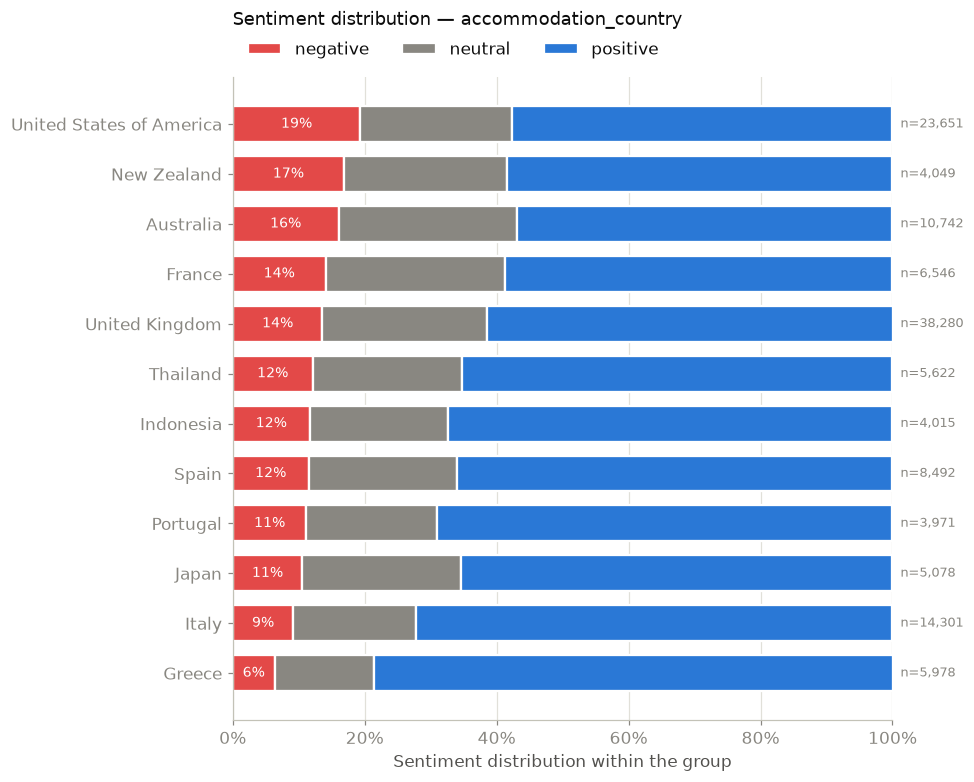

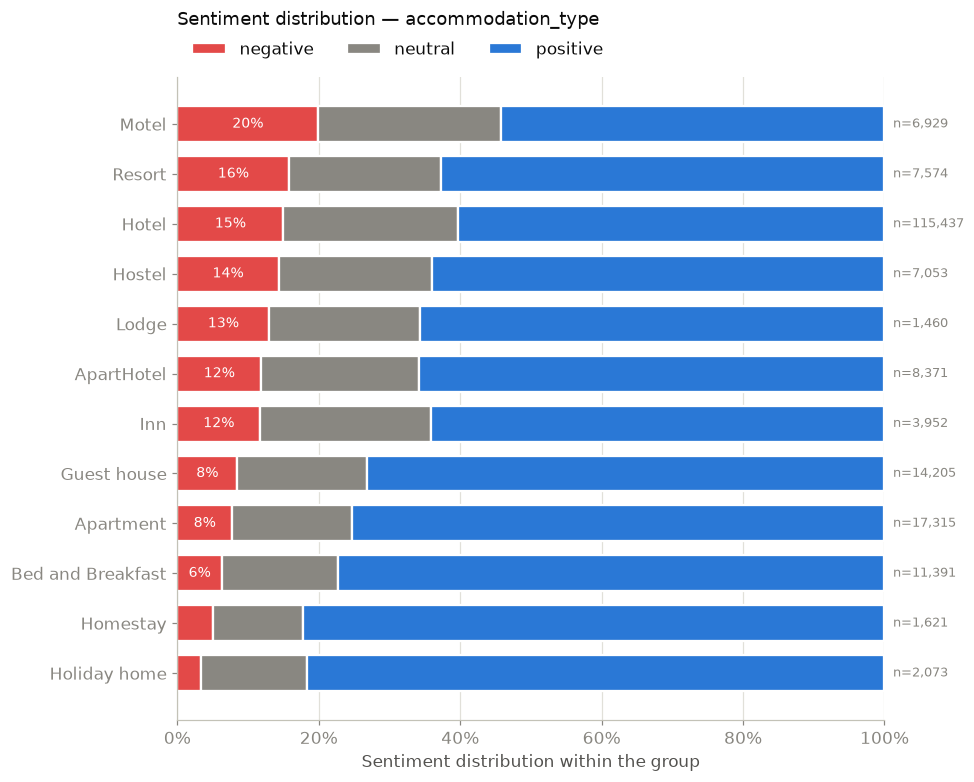

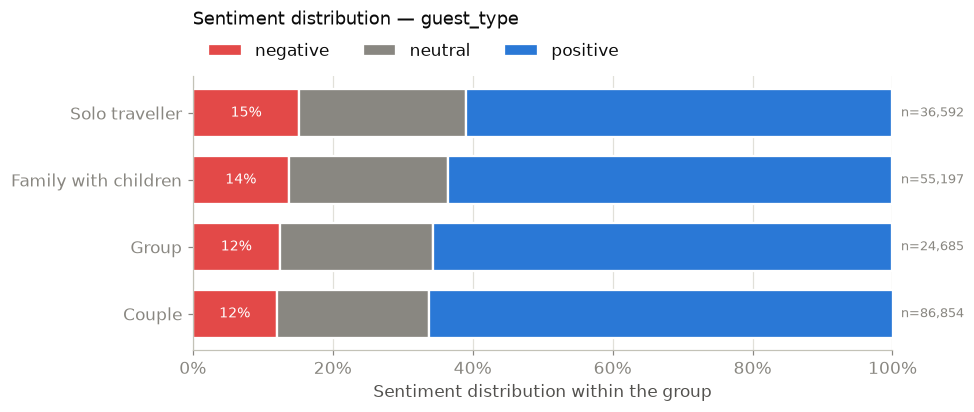

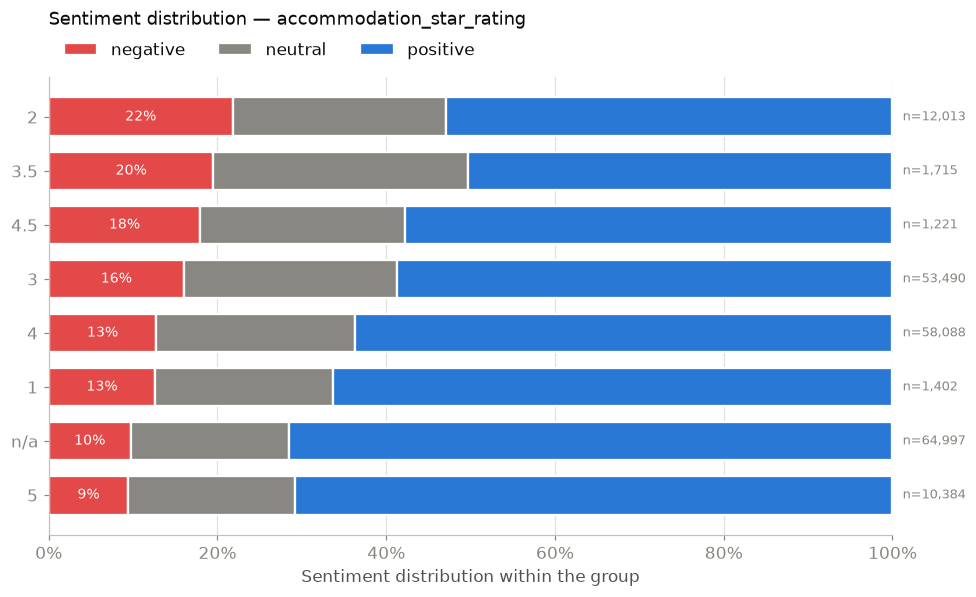

In [63]:
# The figures have already been saved; here they are shown again in the notebook
for col, tab in crosstabs.items():
    ds.plot_sentiment_by(tab, f"Sentiment distribution — {col}")
    plt.show()

### Two dimensions together — heatmap

One-dimensional tables can hide a relationship. For example, hostels may look worse
because they typically have a lower star rating — not because they are hostels.
The crosstab separates the two.

The heatmap uses a **diverging** scale: blue = **fewer** negatives than average,
red = **more**. Diverging, because the question is not "how much?" but "better or
worse than average?" — which has a meaningful midpoint (lift = 1.0).

accommodation_star_rating,2,3,3.5,4,5,n/a
accommodation_type,,,,,,
ApartHotel,1.247,1.051,1.616,1.130,0.884,0.576
Apartment,0.445,0.762,NaN,0.615,0.335,0.585
Bed and Breakfast,NaN,0.912,NaN,0.301,0.186,0.466
Guest house,1.332,0.430,NaN,0.339,0.047,0.682
Hostel,0.672,0.875,NaN,NaN,0.289,1.164
Hotel,1.728,1.271,1.853,1.011,0.709,1.041
Motel,2.319,1.830,1.350,1.066,NaN,0.883
Resort,NaN,1.182,NaN,1.321,0.965,1.054


15:42:05 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_heatmap_type_x_stars.csv
15:42:06 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_heatmap_type_x_stars.png


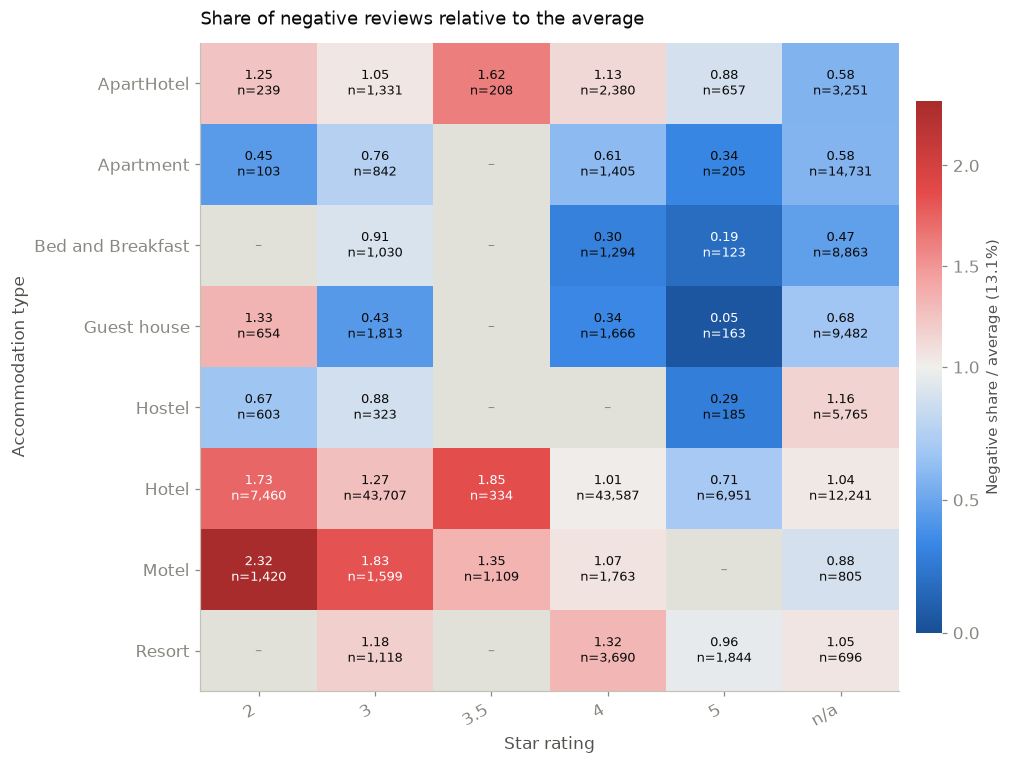

Grey cells: fewer than 100 reviews — not interpretable.


In [64]:
def heatmap(rows, cols, xlabel, ylabel, fname, min_count=100, top_rows=8, top_cols=6):
    """Heatmap in one line, fault-tolerant.

    If every cell gets masked out (too few reviews), the notebook does not stop,
    it prints what to change. On a small sample this tends to happen."""
    if not {rows, cols} <= set(df.columns):
        print(f"Skipped — not both columns are present: {rows}, {cols}")
        return
    try:
        lift, counts, base = ds.negativity_heatmap(
            df, rows=rows, cols=cols,
            min_count=min_count, top_rows=top_rows, top_cols=top_cols,
        )
    except ValueError as e:
        print(f"Skipped: {e}")
        return
    display(lift)
    ev.save_table(lift, fname)
    ds.plot_negativity_heatmap(
        lift, counts, base,
        title="Share of negative reviews relative to the average",
        xlabel=xlabel, ylabel=ylabel, save_as=fname,
    )
    plt.show()
    print(f"Grey cells: fewer than {min_count} reviews — not interpretable.")


# Accommodation type × star rating
heatmap("accommodation_type", "accommodation_star_rating",
        xlabel="Star rating", ylabel="Accommodation type",
        fname="01_heatmap_type_x_stars")

accommodation_type,ApartHotel,Apartment,Bed and Breakfast,Guest house,Hotel,Resort
accommodation_country,,,,,,
Australia,1.355,1.027,0.395,NaN,1.292,1.971
France,1.658,0.977,0.070,0.068,1.119,NaN
Greece,0.376,0.353,NaN,0.072,0.671,0.659
Italy,0.227,0.255,0.349,0.635,0.907,NaN
Japan,0.603,0.866,NaN,0.283,0.797,NaN
New Zealand,NaN,0.483,0.070,NaN,2.111,0.975
Spain,0.766,0.603,0.320,0.984,0.933,NaN
Thailand,NaN,NaN,NaN,1.065,0.836,1.126
United Kingdom,0.556,0.418,0.641,0.580,1.339,NaN


15:42:07 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_heatmap_country_x_type.csv
15:42:08 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_heatmap_country_x_type.png


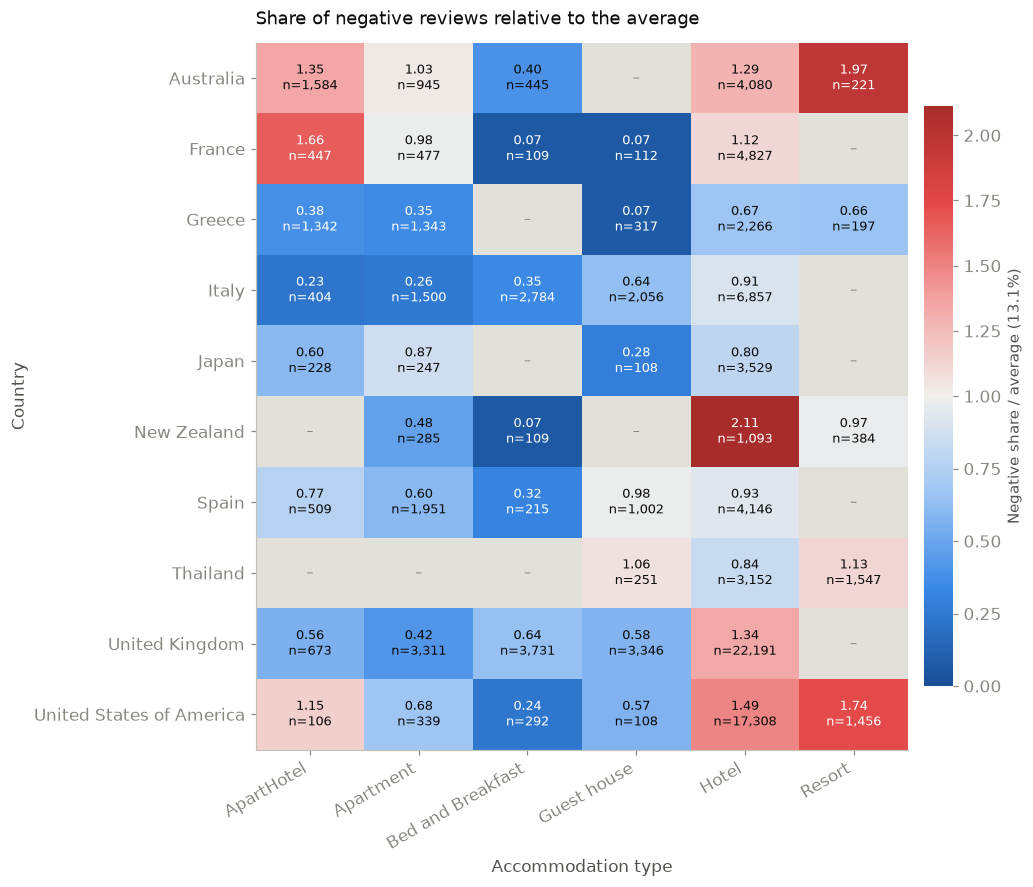

Grey cells: fewer than 100 reviews — not interpretable.


In [65]:
# Country × accommodation type
heatmap("accommodation_country", "accommodation_type",
        xlabel="Accommodation type", ylabel="Country",
        fname="01_heatmap_country_x_type", top_rows=10)

> **Write down in the log what you SEE** (`docs/naplo.md`):
> - Which accommodation type/country drives complaints the most, and by how much?
> - Does the effect disappear if the star rating is taken into account too? (If so,
>   the star rating was the real explanatory variable — an important distinction,
>   and a good illustration of why a crosstab is needed.)
> - Is there a guest type that systematically rates more strictly?
>
> **A warning about wording:** these are **associations**, not causal relationships.
> Do not write "the hostel gives a worse experience", but "in the hostel category
> negative reviews are more frequent than average". Chapter 7 of your thesis already
> records this distinction correctly.

## 8. Aspect preview

In [66]:
# Sentence splitting + keyword-based aspect detection.
# This is the BASELINE the later transformer-based ABSA is compared to (RQ4).
# A slow operation, so it runs on a sample.
sample = df.sample(min(30_000, len(df)), random_state=CFG.random_seed)

sent_df = asp.explode_to_sentences(sample, text_col="text")
sent_df = asp.add_aspect_columns(sent_df, text_col="sentence")

print(f"{len(sample):,} reviews -> {len(sent_df):,} sentences")
print(f"On average {sent_df['n_aspects'].mean():.2f} aspects / sentence")
print(f"No aspect was found in {(sent_df['n_aspects'] == 0).mean():.1%} of the sentences.")
print("\n=> These are the IMPLICIT aspects ('we could not sleep' = noise, without a")
print("   keyword). The transformer will find some of them — this will be one of")
print("   your main arguments for why transformer-based ABSA is needed.")

30,000 reviews -> 126,975 sentences
On average 1.06 aspects / sentence
No aspect was found in 32.4% of the sentences.

=> These are the IMPLICIT aspects ('we could not sleep' = noise, without a
   keyword). The transformer will find some of them — this will be one of
   your main arguments for why transformer-based ABSA is needed.


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
bathroom,6896,0.0543,0.2369,0.2794,0.4836,1.6245,0.7697
wifi,1073,0.0085,0.2116,0.2526,0.5359,1.4505,0.8529
value_for_money,6570,0.0517,0.2105,0.2766,0.5129,1.4432,0.8164
room,28699,0.2260,0.1825,0.2549,0.5626,1.2513,0.8954
noise,4609,0.0363,0.1792,0.2684,0.5524,1.2287,0.8792
parking,2462,0.0194,0.1669,0.2522,0.5808,1.1445,0.9244
facilities,9193,0.0724,0.1655,0.2558,0.5787,1.1344,0.9211
pool,3325,0.0262,0.1507,0.2400,0.6093,1.0331,0.9698
location,25481,0.2007,0.1375,0.2416,0.6209,0.9425,0.9883


15:42:15 | INFO    | src.evaluation | Table saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_aspect_sentiment_distribution.csv
15:42:16 | INFO    | src.evaluation | Figure saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_aspect_sentiment_stacked.png


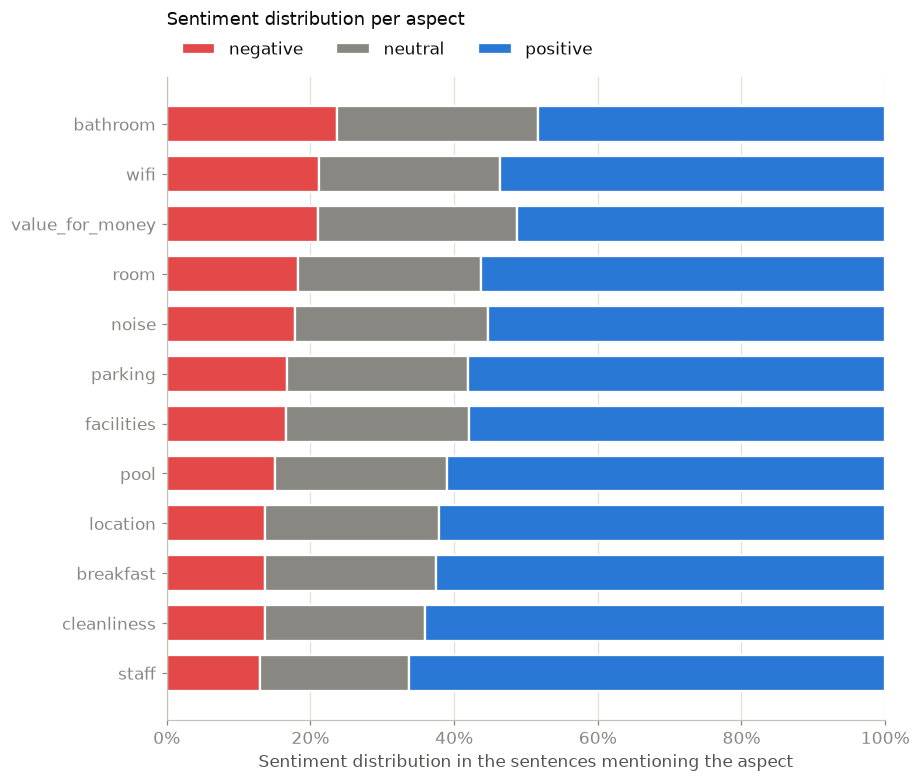

In [67]:
# THE FIRST ANSWER TO RQ3: which aspects are tied to negative sentiment?
aspect_table = asp.aspect_sentiment_table(sent_df, min_count=100)
display(aspect_table)
ev.save_table(aspect_table, "01_aspect_sentiment_distribution")

asp.plot_aspect_sentiment(aspect_table, save_as="01_aspect_sentiment_stacked")
plt.show()

In [68]:
# Concrete examples: what does the extraction of "textual evidence" look like?
neg_sent = sent_df[(sent_df["sentiment"].astype(str) == "negative") &
                   (sent_df["n_aspects"] > 0)].head(8)

for _, r in neg_sent.iterrows():
    print(f"SENTENCE: {r['sentence'][:150]}")
    for a in r["aspects"]:
        spans = asp.extract_evidence(r["sentence"], a)
        if spans:
            flag = "   [NEGATION!]" if asp.has_negation(spans[0]) else ""
            print(f'   • {a:16s} -> "{spans[0]}"{flag}')
    print()

SENTENCE: Close by the main square, lovely and clean , amenities close by , great bathroom , staff online were great about a late check out and storing our case
   • staff            -> ", great bathroom , staff online were great about"
   • cleanliness      -> "main square, lovely and clean , amenities close by"
   • facilities       -> "lovely and clean , amenities close by , great"
   • bathroom         -> "close by , great bathroom , staff online were"

SENTENCE: Pillows were awful and very lumpy , smoke alarm had no batteries and in a draw, picture for the room still in the cupboard.
   • room             -> "Pillows were awful and very"

SENTENCE: Wi-Fi wouldn’t work for 2 days .
   • wifi             -> "Wi-Fi wouldn’t work for 2"

SENTENCE: I did like the room but it was nothing like the pictures it was very plain .
   • room             -> "I did like the room but it was nothing"   [NEGATION!]

SENTENCE: fine for one night at a low cost.
   • value_for_money  -> "night at a lo

> **Collect in the log where the keyword method fails.** Look for examples:
> negation ("the room was **not** clean"), irony, implicit aspects, several aspects
> with opposite sentiment in one sentence. This list will be the justification for
> RQ4 — and a valuable subsection of its own.
>
> **A methodological limitation that has to be described:** here the *review-level*
> sentiment is projected onto the sentences, which is an approximation. A review with
> a positive overall score can contain a negative sentence too. Accurate sentence-level
> labels need the HRAST dataset (phase 4).

## 9. Split and saving

In [69]:
train_df, val_df, test_df = pp.train_val_test_split(df)

# Check: have the class proportions been kept in all three sets?
check = pd.DataFrame({
    "train": train_df["sentiment"].value_counts(normalize=True),
    "val":   val_df["sentiment"].value_counts(normalize=True),
    "test":  test_df["sentiment"].value_counts(normalize=True),
}).reindex(list(CFG.labels)).round(4)
display(check)
print("The three columns should be almost identical -> the stratification works.")

15:42:16 | INFO    | src.preprocessing | Split — train: 121996 | val: 40666 | test: 40666


,train,val,test
sentiment,,,
negative,0.1309,0.1309,0.1309
neutral,0.2243,0.2243,0.2243
positive,0.6448,0.6448,0.6448


The three columns should be almost identical -> the stratification works.


In [70]:
# Saving. Notebooks 02 and 03 load FROM HERE, so all three models work on
# EXACTLY the same split — without this the RQ1 comparison would be meaningless.
keep = ["review_id", "text", "text_clean", "text_bert", "score", "sentiment", "dataset"]
# The metadata is carried along too, so the error analysis can group by it
# (e.g. "for which accommodation type does the model make the most errors?")
keep += [c for c in ["accommodation_type", "accommodation_country",
                     "accommodation_star_rating", "guest_type"] if c in df.columns]

dl.save_splits({
    "train": train_df[keep],
    "val":   val_df[keep],
    "test":  test_df[keep],
})

# Save the configuration next to the data as well — so for every later result
# you will know exactly which settings produced this split.
CFG.to_json(PATHS.processed / "config_snapshot.json")
print("\nConfiguration saved: config_snapshot.json")

15:42:17 | INFO    | src.data_loading | train  -> booking_train.parquet          (121996 rows)
15:42:17 | INFO    | src.data_loading | val    -> booking_val.parquet            (40666 rows)
15:42:17 | INFO    | src.data_loading | test   -> booking_test.parquet           (40666 rows)



Configuration saved: config_snapshot.json


---

## Summary — what has been produced

### Figures (`results/figures/`)

| File | Thesis chapter |
|---|---|
| `01_eda_overview.png` | 9. EDA — score, classes, lengths |
| `01_top_words_by_sentiment.png` | 9. EDA — what drives the sentiment |
| `01_counts_*.png` | 9. EDA — composition of the sample |
| `01_crosstab_*.png` | **9. EDA — the main figures of the descriptive analysis** |
| `01_heatmap_*.png` | 9. EDA — two dimensions together |
| `01_aspect_sentiment_stacked.png` | 7. ABSA / RQ3 |

### Tables (`results/tables/`)

| File | Thesis chapter |
|---|---|
| `01_dataset_overview.csv` | 4. Data Sources |
| `01_label_scheme_comparison.csv` | **6.1 — justification of the threshold choice** |
| `01_numeric_profile.csv` | 9. EDA |
| `01_crosstab_*.csv` | 9. EDA |
| `01_heatmap_*.csv` | 9. EDA |
| `01_aspect_sentiment_distribution.csv` | **The first answer to RQ3** |

### Data (`data/processed/`)

`booking_train.parquet`, `booking_val.parquet`, `booking_test.parquet` —
notebooks 02 and 03 work from these.

---

## NOW write the log

Open `docs/naplo.md` and answer:

1. **Why `val.csv`?** (subset, computational cost, representativeness)
2. **What is the licence, and how do you cite it?** (CC BY-SA 4.0)
3. **Why 7/9 as the threshold?** — supported by the sensitivity table
4. **What did the filtering throw out?** — with the concrete numbers of the filtering log
5. **What is striking in the distributions?** (imbalance, length difference)
6. **What do the crosstabs show?** — which group drives complaints, and does the
   effect disappear when another dimension is included
7. **Where does the keyword-based aspect detection fail?**

> These seven points are the raw material for chapters 4, 6.1, 7 and 9 of the thesis.
> It is much easier to write them down now than to recall them three months from now.

**Commit:**
```
git add .
git commit -m "Notebook 01 run: EDA, crosstabs, splits saved"
```

**Next:** `02_classical_baseline.ipynb` — TF-IDF + Naive Bayes / LogReg / SVM.